### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 6
### Due: Wed. Nov 4, at 11.59pm CT
---

This problem has to do with density estimation and clustering. 

1. Read in `hw6_data_1.npy`. The dataset should consist of $1000$ samples with $2$ features. Note that the last column are the labels, not another feature. Make a $2$-D scatter plot of the data colored by their labels. 


2. Start with kernel density estimation on the data set. First, perform a grid search $5$-fold cross-validation to find the best bandwidth, testing $30$ bandwidths between $0.1$ and $1.0$. What is this best bandwidth? Using this best bandwidth, plot the two-dimensional kernel density estimate of the distribution. 


3. Now try a nearest neighbors approach to estimating the density. Use the Bayesian nearest neighbors option. Plot the estimated distribution. What value of $k$ neighbors do you need to make the plot look similar to your KDE distribution?


4. Now fit a Gaussian mixture model. Compute the AIC and BIC for the number of GMM components between $1$ and $10$. Plot these AIC and BIC values as a function of number of components. What is the optimal number according to the BIC? Fit the data set with this optimal number of GMM components, and create a new plot that shows the data set, the GMM component mean locations, and the $2$-sigma GMM component ellipses. *(Use the code below to help with plotting the ellipses.)*

In [1]:
# Kludge to fix the bug with draw_ellipse in astroML
from matplotlib.patches import Ellipse

def draw_ellipse(mu, C, scales=[1, 2, 3], ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()

    # find principal components and rotation angle of ellipse
    sigma_x2 = C[0, 0]
    sigma_y2 = C[1, 1]
    sigma_xy = C[0, 1]

    alpha = 0.5 * np.arctan2(2 * sigma_xy,
                          (sigma_x2 - sigma_y2))
    tmp1 = 0.5 * (sigma_x2 + sigma_y2)
    tmp2 = np.sqrt(0.25 * (sigma_x2 - sigma_y2) ** 2 + sigma_xy ** 2)

    sigma1 = np.sqrt(tmp1 + tmp2)
    sigma2 = np.sqrt(tmp1 - tmp2)

    for scale in scales:
        ax.add_patch(Ellipse(xy=(mu[0], mu[1]),
                          width=2 * scale * sigma1, height=2 * scale * sigma2,
                          angle=alpha * 180. / np.pi,
                          **kwargs))

5. Now try Kmeans clustering with $5$ clusters. 
    - Use the `StandardScalar` to scale the data.
    - Fit the Kmeans model.
    - Find the cluster centers, and then inverse transform thse cluster centers back to the original unscaled coordinates.
    - Predict the labels for the scaled data.
    - Finally, make a two-panel side by side plot showing (a) the original data colored by its labels, then (b) the data colored by the Kmeans predicted labels, with cluster centers superposed.

### Solution

In [2]:
#part 1
#imports
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#load data
data = np.load("hw_data/hw6_data_1.npy")
features = data[:, :2]
labels = data[:, -1]

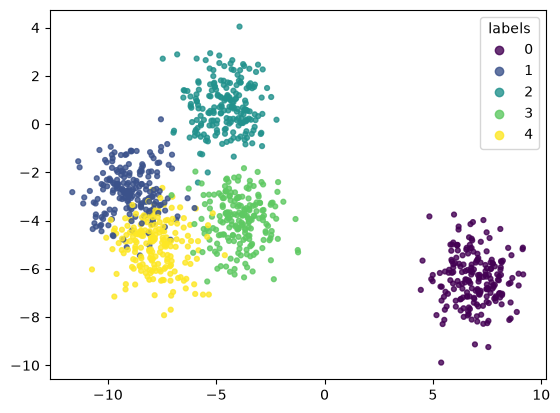

In [4]:
#plot
scatter = plt.scatter(features[:, 0], features[:, 1], c=labels, s=12, alpha=0.8)
plt.legend(*scatter.legend_elements(), title="labels")
plt.show()

In [5]:
#part 2
#imports
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

In [6]:
#from lecture 14
#test 30 bandwidths
bwrange = np.linspace(0.1, 1.0, 30) 
#5-fold
K = 5 
#cross-validation
grid = GridSearchCV(KernelDensity(), {'bandwidth': bwrange}, cv=K) 
grid.fit(features) 
h_opt = grid.best_params_['bandwidth']
print("best bandwidth:", h_opt)

best bandwidth: 0.4724137931034482


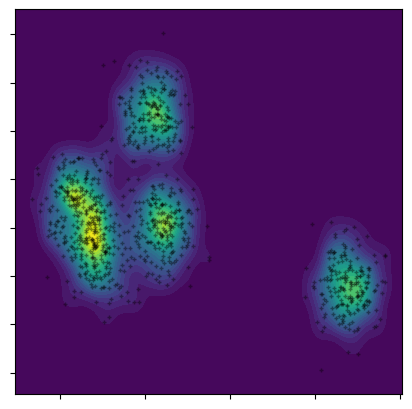

In [7]:
#plot
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111)
ax.xaxis.set_major_formatter(plt.NullFormatter())
ax.yaxis.set_major_formatter(plt.NullFormatter())

#get kernel density estimate
kde = KernelDensity(bandwidth=h_opt).fit(features)

#create grid of points
xx = np.linspace(features[:, 0].min() - 1, features[:, 0].max() + 1, 200)
yy = np.linspace(features[:, 1].min() - 1, features[:, 1].max() + 1, 200)
x_grid, y_grid = np.meshgrid(xx, yy)

#density values
density = np.exp(kde.score_samples(np.c_[x_grid.ravel(), y_grid.ravel()])).reshape(x_grid.shape)

#finish setting up plot
ax.contourf(x_grid, y_grid, density, levels=30)
ax.plot(features[:, 0], features[:, 1], '+k', ms=3, alpha=0.4)
ax.set_xlim(x_grid.min(), x_grid.max())
ax.set_ylim(y_grid.min(), y_grid.max())
plt.show()

In [8]:
#part 3
#import
from astroML.density_estimation import KNeighborsDensity

In [9]:
#k neighbor values to try
ks = [50, 100, 150, 200]

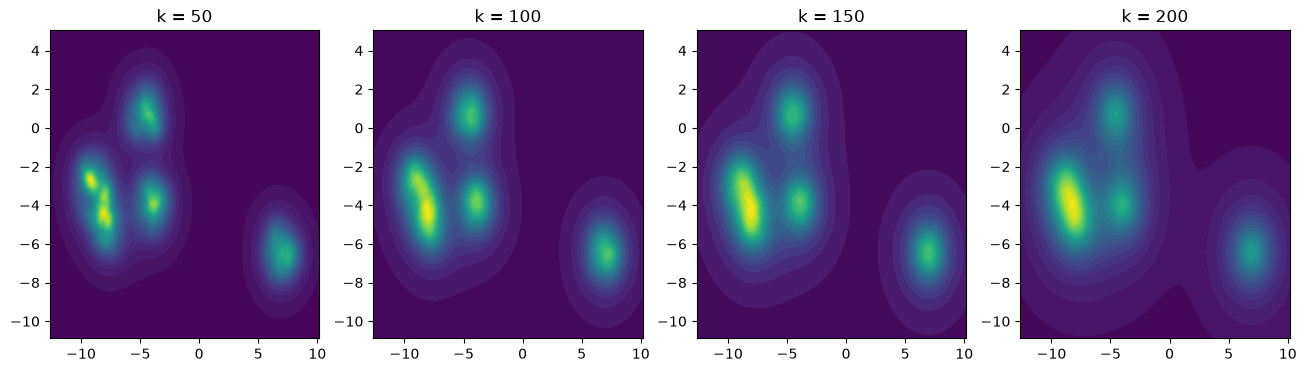

In [10]:
#plot
fig, axes = plt.subplots(1, len(ks), figsize=(4 * len(ks), 4))
N = len(features)

#loop to repeat process for each k neighbor value and plot
for ax, k in zip(axes, ks):
    knn = KNeighborsDensity('bayesian', n_neighbors=k).fit(features)
    dens = (knn.eval(np.c_[x_grid.ravel(), y_grid.ravel()]) / N).reshape(x_grid.shape)
    ax.contourf(x_grid, y_grid, dens, levels=30)
    ax.set_title(f"k = {k}")

plt.show()

In [11]:
#k = 150 looks similar to KDE distribution

In [12]:
#part 4
#import
from sklearn.mixture import GaussianMixture

In [13]:
#compute the AIC and the BIC
#from lecture 14
N2 = np.arange(1, 11)
models = [GaussianMixture(n, random_state=0).fit(features) for n in N2]
AIC = [m.aic(features) for m in models]
BIC = [m.bic(features) for m in models]

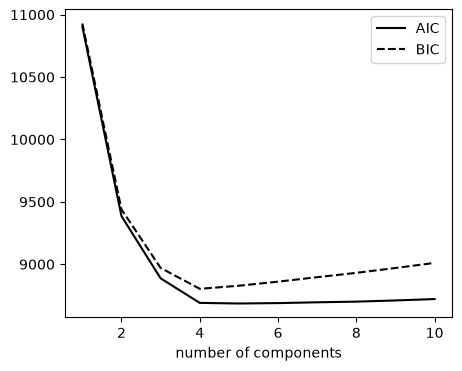

In [14]:
#plot AIC and BIC
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(111)
ax.plot(N2, AIC, '-k', label='AIC')
ax.plot(N2, BIC, '--k', label='BIC')
ax.set_xlabel('number of components')
ax.legend()
plt.show()

In [16]:
#find optimal number
n_opt = N2[np.argmin(BIC)]
print("optimal number of components:", n_opt)
M_best = models[np.argmin(BIC)]

optimal number of components: 4


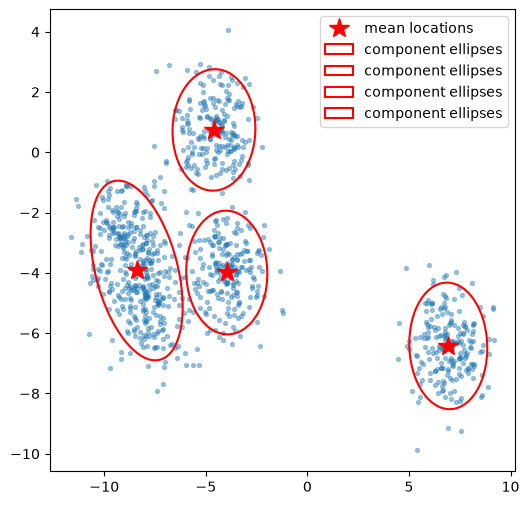

In [17]:
#plot
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(features[:, 0], features[:, 1], s=8, alpha=0.4)
ax.plot(M_best.means_[:, 0], M_best.means_[:, 1], 'r*', ms=15, label='mean locations')

#create ellipses around mean locations
for mean, cov in zip(M_best.means_, M_best.covariances_):
    draw_ellipse(mean, cov, scales=[2], ax=ax, fc='none', ec='r', lw=1.5, label='component ellipses')

ax.legend()
plt.show()

In [18]:
#part 5
#imports
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [19]:
#scale data
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

In [20]:
#fit KMeans model
kmeans = KMeans(n_clusters=5, n_init=10, random_state=0).fit(features_scaled)

In [21]:
#find cluster centers
centers_scaled = kmeans.cluster_centers_
#inverse transform
centers = scaler.inverse_transform(centers_scaled)

In [22]:
#predict labels
pred_labels = kmeans.predict(features_scaled)

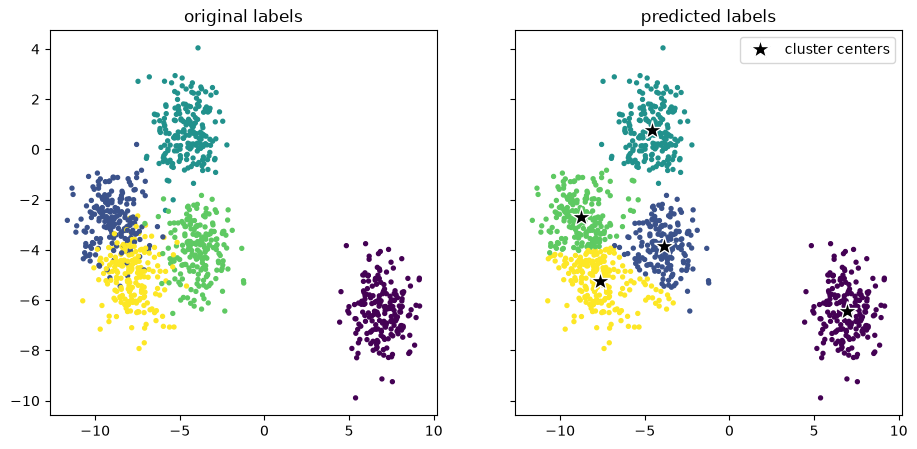

In [23]:
#plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)

ax1.scatter(features[:, 0], features[:, 1], c=labels, s=8)
ax1.set_title('original labels')

ax2.scatter(features[:, 0], features[:, 1], c=pred_labels, s=8)
ax2.plot(centers[:, 0], centers[:, 1], 'k*', ms=15, mec='w', label='cluster centers')
ax2.set_title('predicted labels')
ax2.legend()

plt.show()